# Changing codes: a fold-transversal Hadamard, step by step

> **In short.**
> * **The idea.** A *transversal* gate is the same gate on every qubit at once, so a fault in one gate touches one qubit only. On the surface code, a Hadamard on every qubit is a logical Hadamard, but it changes the code: a Hadamard swaps $X$ and $Z$, so every $X$ check becomes a $Z$ check and the other way round. A *fold-transversal* Hadamard (Moussa 2016; Breuckmann and Burton 2024) then rearranges the qubits so that every check is back in its place. In the circuit used here, the rearrangement is a quarter turn of the grid. The code changes twice in one program.
> * **What it shows.** Question 1 follows the code through the program; the Hadamard block is a logical Hadamard and the whole program a Hadamard in every run, up to Paulis that the results determine; and a check wired to the wrong qubit, a mistake in the original circuit files, shows up: for one stage the code can no longer catch a single error.
> * **The sections** follow the paper's section: (1) the surface code, (2) the program, (3) Question 1, the code after every stage, (4) Questions 2 and 3, (5) the check on the wrong qubit, (6) the levels window.
> * **Library calls only**: `build_program` of [interactive_fold_h_3d.py](interactive_fold_h_3d.py) (the eight original OpenQASM files as a `QProgram`), `code_at`, `same_code_as`, `StabilizerCode.draw_layout`, `group_stages`, `summary`, `logical_action`, `phases_modulo`, `draw_program`, `view_levels`. The interactive windows are [interactive_fold_h_levels.py](interactive_fold_h_levels.py) and, in 3D, [interactive_fold_h_levels_3d.py](interactive_fold_h_levels_3d.py).

In [1]:
%matplotlib inline
import pyzx as zx
from IPython.display import display
import interactive_fold_h_3d as fth          # build_program: the original OpenQASM files as a QProgram
from zxqec.gpf import phases_modulo
from zxqec.spacetime import draw_program, view_levels

p = fth.build_program()
coords = {q: p.topology.nodes[q] for q in range(1, 10)}       # where the nine data qubits sit on the chip

## 1. The surface code (Fig. 1a)

The distance-3 surface code stores one qubit in nine, on a $3 \times 3$ grid. Question 1 reads it off the program right after stage 0 (`code_at(0)`; `data()` leaves out the helpers, still in $|0\rangle$).

* **Checks.** Each red patch is an $X$ check on the qubits at its corners, each green patch a $Z$ check: four of each, on four qubits or, at the edge (the half discs), on two. A *stabilizer* in the printout is a check; its sign $(-1)^{c[k]}$ is set by a result of the first round.
* **What they catch.** A $Z$ check returns 1 when an odd number of its qubits have an $X$ error, an $X$ check the same for $Z$ errors, so every error on one qubit makes some check return 1.
* **The stored qubit.** Its logical $X$ is $X$ on a column (dashed red), its logical $Z$ is $Z$ on a row (dashed green).

[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
    stabilizer (-1)^(c[2])IXXIIIIII
    stabilizer (-1)^(c[3])IIIIIIXXI
    stabilizer (-1)^(c[1])XXIXXIIII
    stabilizer (-1)^(c[4])IIIIXXIXX
    stabilizer +ZIIZIIIII
    stabilizer +IIIIIZIIZ
    stabilizer +ZIIIZIZZI
    stabilizer +IZZIZZIII
    logical X XIIXIIXII   logical Z ZZZIIIIII


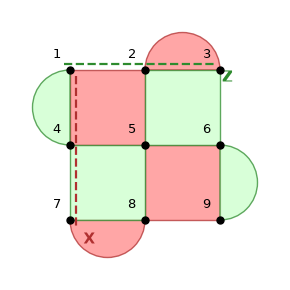

In [2]:
print(p.code_at(0).data())
p.code_at(0).draw_layout(coords, figsize=(3, 3))

`draw_layout` draws the checks of `layout_checks`: a set of checks that generates them all, the fewest qubits and the smallest area on the grid first, which on a surface code are its patches. The printout lists another generating set (for example $Z_1Z_5Z_7Z_8$, the product of two patches).

In [3]:
print(p.code_at(0).layout_checks(coords))

{'X': [(2, 3), (7, 8), (1, 2, 4, 5), (5, 6, 8, 9)], 'Z': [(1, 4), (6, 9), (2, 3, 5, 6), (4, 5, 7, 8)]}


## 2. The program (Fig. 2)

The program: eight OpenQASM files on 19 qubits, read by PyZX. Qubits 1–9 are the grid, 10–17 the helpers that measure the checks (one per patch), qubit 0 the input and qubit 18 the output. The stages:

| stage | what it does |
|---|---|
| 0 | copy the input into the code and measure the $X$ checks |
| 1 | a Hadamard on each of the nine qubits |
| 2, 3 | a round of checks of the new code |
| 4 | the quarter turn: a permutation that moves each qubit to its place on the turned grid |
| 5, 6 | a round of checks of the surface code |
| 7 | a last round of $Z$ checks, then the stored qubit is copied out to qubit 18 and the grid is measured |

The 35 measurement results `c[0]`–`c[34]` are Boolean variables. We level the stages up into six blocks; the drawing is shaded by them. A blue edge is a Hadamard; the crossing wires in *rotate* are the quarter turn.

Level 0 (8 blocks):
  Block 0 'encode + X checks': [encode + X checks]
  Block 1 'transversal H': [transversal H]
  Block 2 'Z checks (code 2)': [Z checks (code 2)]
  Block 3 'X checks (code 2)': [X checks (code 2)]
  Block 4 'rotate 90°': [rotate 90°]
  Block 5 'Z checks': [Z checks]
  Block 6 'X checks': [X checks]
  Block 7 'Z checks + decode': [Z checks + decode]
Level 6 (6 blocks):
  Block 0 'encode + round 1' (encoder): [encode + X checks]
  Block 1 'transversal H' (logical gate): [transversal H]
  Block 2 'round in code 2' (syndrome extraction): [Z checks (code 2), X checks (code 2)]
  Block 3 'rotate' (logical gate): [rotate 90°]
  Block 4 'round in code 1' (syndrome extraction): [Z checks, X checks]
  Block 5 'checks + decode' (decoder): [Z checks + decode]
measurement results: 35


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


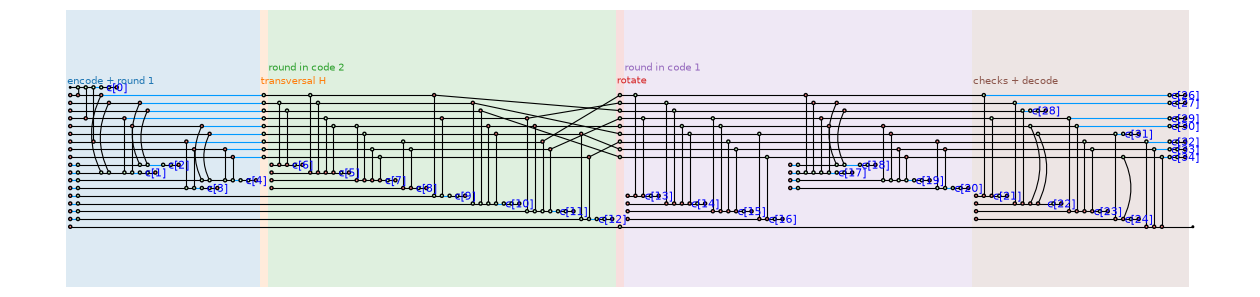

In [4]:
GROUPS = [(0, 0, 'encode + round 1', 'encoder'), (1, 1, 'transversal H', 'logical gate'),
          (2, 3, 'round in code 2', 'syndrome extraction'), (4, 4, 'rotate', 'logical gate'),
          (5, 6, 'round in code 1', 'syndrome extraction'), (7, 7, 'checks + decode', 'decoder')]
blocks = p.group_stages(GROUPS)
print(p.describe_level(0))
print(p.describe_level(blocks))
print("measurement results:", p.bits)
draw_program(p, blocks, time_axis=False, show_time=False, even_rows=True, labels_above=True, figsize=(16, 3.6))

Stage 1 as read from its file, and the quarter turn: program qubit $q$ moves to position `rotation[q]` on the chip ($1 \to 3 \to 9 \to 7 \to 1$, $2 \to 6 \to 8 \to 4 \to 2$, 5 stays).

In [5]:
print(p.stage_circuit(1).to_qasm())
print("positions of qubits 1-9 after the quarter turn:", p.mapping_at(5)[1:10])

OPENQASM 2.0;
include "qelib1.inc";
qreg q[19];
h q[1];
h q[2];
h q[3];
h q[4];
h q[5];
h q[6];
h q[7];
h q[8];
h q[9];

positions of qubits 1-9 after the quarter turn: (3, 6, 9, 2, 5, 8, 1, 4, 7)


## 3. Question 1: the code after every stage (Fig. 1)

Question 1 reads the code after each stage. The printouts below, then the pictures:

* **After stage 0:** the surface code, [[9,1,3]].
* **After the Hadamards (stage 1):** a [[9,1,3]] code again, but a different one: every check has changed colour, and the logical $X$ is now a row.
* **Stages 2–3** keep it.
* **After the quarter turn (stage 4):** the turn does nothing to the state of any qubit, so qubit by qubit the code is still that of stage 1. But each qubit now sits elsewhere on the chip, and compared by position (`same_code_as(..., by='position')`) it is the surface code again: the picture is that of stage 0, with the numbers turned.
* **Stages 5–6** keep it, and stage 7 hands the stored qubit to qubit 18, the code with no checks on one qubit, [[1,1,1]].

In [6]:
for s in range(p.num_stages):
    c = p.code_at(s).data()
    print("after stage {} ({}): [[{}, {}, {}]] on qubits {}{}".format(
        s, p.stage(s), *c.parameters, ', '.join(map(str, c.qubits)),
        " at positions " + ', '.join(map(str, c.positions)) if c.positions and tuple(c.positions) != tuple(c.qubits) else ""))
print()
print("after stage 1, the same code as after stage 0:", p.code_at(1).same_code_as(p.code_at(0)))
print("after stage 4, the same code as after stage 1, qubit by qubit:", p.code_at(4).same_code_as(p.code_at(1)))
print("after stage 4, the same code as after stage 0, by position on the chip:", p.code_at(4).same_code_as(p.code_at(0), by='position'))
print("after stage 6, the same code as after stage 4:", p.code_at(6).same_code_as(p.code_at(4)))

after stage 0 (encode + X checks): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
after stage 1 (transversal H): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
after stage 2 (Z checks (code 2)): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
after stage 3 (X checks (code 2)): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
after stage 4 (rotate 90°): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 at positions 3, 6, 9, 2, 5, 8, 1, 4, 7
after stage 5 (Z checks): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 at positions 3, 6, 9, 2, 5, 8, 1, 4, 7
after stage 6 (X checks): [[9, 1, 3]] on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 at positions 3, 6, 9, 2, 5, 8, 1, 4, 7
after stage 7 (Z checks + decode): [[1, 1, 1]] on qubits 18

after stage 1, the same code as after stage 0: False


after stage 4, the same code as after stage 1, qubit by qubit: True
after stage 4, the same code as after stage 0, by position on the chip: True


after stage 6, the same code as after stage 4: True


after the Hadamards:
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9
    stabilizer +XIIXIIIII
    stabilizer +IIIIIXIIX
    stabilizer +XIIIXIXXI
    stabilizer +IXXIXXIII
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII

after the quarter turn:
[[9, 1, 3]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 (at positions 3, 6, 9, 2, 5, 8, 1, 4, 7)
    stabilizer +XIIXIIIII
    stabilizer +IIIIIXIIX
    stabilizer +XIIIXIXXI
    stabilizer +IXXIXXIII
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII


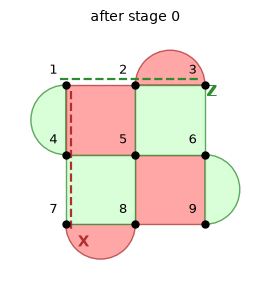

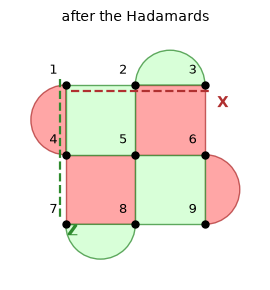

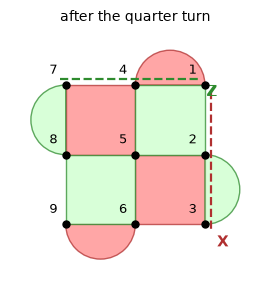

In [7]:
print("after the Hadamards:"); print(p.code_at(1).data()); print()
print("after the quarter turn:"); print(p.code_at(4).data())
for s, name in ((0, 'after stage 0'), (1, 'after the Hadamards'), (4, 'after the quarter turn')):
    display(p.code_at(s).draw_layout(coords, figsize=(3, 3), title=name))

## 4. Questions 2 and 3: every block, and the whole program (Figs. 3, 4)

`summary` answers Questions 2 and 3 for each block. The block *transversal H* is a logical Hadamard, in every run; every other block leaves the stored qubit alone; the first takes it into the code and the last takes it out. *Every run* is up to Paulis that the results determine.

In [8]:
print(p.summary(blocks))

block               role                 code before  code after  logical action  every run?  checks
0 encode + round 1  encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H     logical gate         [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 2   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 rotate            logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 round in code 1   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 checks + decode   decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok

Block 0 'encode + round 1' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 0
  code after:  [[9,1,3]] on qubits 1,2,3,4,5,6,7,8,9
  logical action: deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (Z, none) that the outcomes determine
  measurements: 5 (5 frame)
  ok

For the whole program, the reduction leaves two spiders: a Hadamard on the input (the blue edge), then a green spider with phase $(c_{26}+c_{29}+c_{32})\pi$, a $Z$ when that parity is 1, and a red spider with phase $(c_0+\dots+c_4)\pi$, an $X$ when that parity is 1. $c_{26}, c_{29}, c_{32}$ are the readouts of one column of the grid, which is the logical $X$; $c_0, \dots, c_4$ are the input's measurement and the first round. A decoder applies these Paulis or keeps track of them. The other results go into 24 detectors, parities that are 0 in every run. With every result set to 0, the program is the Hadamard alone.

deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (X, Y, Z, none) that the outcomes determine
  when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 0: H, then nothing
  when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1: H, then Z
  when c[4] + c[0] + c[3] + c[1] + c[2] = 1 and c[29] + c[26] + c[32] = 0: H, then X
  when c[4] + c[0] + c[3] + c[1] + c[2] = 1 and c[29] + c[26] + c[32] = 1: H, then Y
24 detectors, e.g. c[6] + c[2] = 0, c[5] + c[1] = 0, c[7] + c[4] = 0, c[8] + c[3] = 0 ...


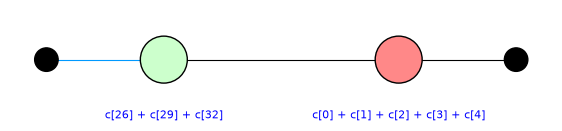

In [9]:
whole = p.level_up(blocks, 0, len(GROUPS) - 1, name='whole program')
action = p.logical_action(whole, 0)
print(action.verdict())
for b in action.branches():
    print("  {}: {}, then {}".format(b.when(), b.operation, b.correction or 'nothing'))
print(len(action.detectors), "detectors, e.g.", ", ".join("{} = 0".format(d) for d in list(action.detectors)[:4]), "...")
zx.draw_matplotlib(phases_modulo(action.result.to_graph(), action.result.constraints), figsize=(7, 1.3))

## 5. A check on the wrong qubit (Fig. 5)

In the original circuit files, one $Z$ check of stage 5 used the wrong qubit: `cx q[2], q[14];` where `cx q[4], q[14];` was meant (stage 5 is written in the chip's numbering; `build_program(miswired=True)` puts the wrong line back). With every result set to 0 the program still gives a Hadamard, so checking with all results 0 misses it. With the results kept as variables, three answers change.

**(a) `summary` flags the block *round in code 1*:** its result `c[13]` affects nothing and is never checked again. The whole program has 22 detectors instead of 24, and the $Z$ correction now also depends on `c[18]`.

In [10]:
bad = fth.build_program(miswired=True)
print("stage 5, the check with helper 14, as in the corrected file (chip numbering):",
      [line for line in fth.load('ft_h_5').to_qasm().splitlines() if 'q[14]' in line])
bad_blocks = bad.group_stages(GROUPS)
print(bad.summary(bad_blocks))
bad_action = bad.logical_action(bad.level_up(bad_blocks, 0, len(GROUPS) - 1, name='whole program'), 0)
print(len(bad_action.detectors), "detectors")
for b in bad_action.branches():
    print("  {}: {}, then {}".format(b.when(), b.operation, b.correction or 'nothing'))

stage 5, the check with helper 14, as in the corrected file (chip numbering): ['cx q[1], q[14];', 'cx q[4], q[14];', 'measure q[14] -> c[13];']


block               role                 code before  code after  logical action  every run?  checks
0 encode + round 1  encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 transversal H     logical gate         [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 round in code 2   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 rotate            logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 round in code 1   syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         1 problem(s)
5 checks + decode   decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok

Block 0 'encode + round 1' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 0
  code after:  [[9,1,3]] on qubits 1,2,3,4,5,6,7,8,9
  logical action: deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (Z, none) that the outcomes determine
  measurements: 5 (5 f

**(b) Question 1 right after stage 5 reads a [[9,1,1]] code.** The wrong check measures $Z$ on the chip's qubits 1 and 2, which is not a check of the surface code. It removes the $X$ check on chip qubits 2 and 3 (compare the picture with the one after the quarter turn in section 3: a green half disc on the left of the top edge, and no red one on its right), and the logical $Z$ becomes a $Z$ on one qubit, program qubit 1, in the top right corner. The distance has dropped from 3 to 1. After stage 6 the code is [[9,1,3]] again.

[[9, 1, 1]] CSS code on qubits 1, 2, 3, 4, 5, 6, 7, 8, 9 (at positions 3, 6, 9, 2, 5, 8, 1, 4, 7)
    stabilizer +IIIIIXIIX
    stabilizer +IXXIXXIII
    stabilizer +IIIXXIXXI
    stabilizer (-1)^(c[2])IZZIIIIII
    stabilizer (-1)^(c[13])IIIZIIZII
    stabilizer (-1)^(c[3])IIIIIIZZI
    stabilizer (-1)^(c[1])ZZIZZIIII
    stabilizer (-1)^(c[4])IIIIZZIZZ
    logical X XXXIIIIII   logical Z ZIIIIIIII
after stage 6: (9, 1, 3)


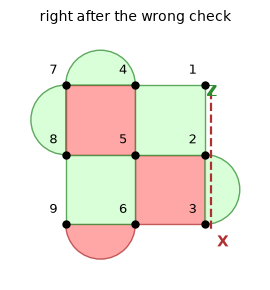

In [11]:
print(bad.code_at(5).data())
print("after stage 6:", bad.code_at(6).data().parameters)
bad.code_at(5).draw_layout(coords, figsize=(3, 3), title='right after the wrong check')

**(c) Distance 1 means that one error can change the stored qubit without any check seeing it.** We put one $Z$ error on that corner qubit (grid position 3) right after stage 5 (`build_program(z_error=3)`). In the correct program two detectors then read 1, `c[18]` and `c[27] + c[28]`: the error is caught. In the mis-wired one the 22 detectors are unchanged and the $Z$ correction flips: every run ends with an extra logical $Z$.

In [12]:
for miswired in (False, True):
    clean = fth.build_program(miswired=miswired).logical_action()
    hit = fth.build_program(miswired=miswired, z_error=3).logical_action()
    changed = sorted(set(map(str, hit.detectors)) - set(map(str, clean.detectors)))
    print("mis-wired:" if miswired else "correct:", len(hit.detectors), "detectors; with the error they read",
          ", ".join(d + " = 0" for d in changed) if changed else "the same as without it")
    print("   Z correction without the error:", [b.when() for b in clean.branches() if b.correction == 'Z'][0])
    print("   Z correction with the error:   ", [b.when() for b in hit.branches() if b.correction == 'Z'][0])

correct: 24 detectors; with the error they read c[18] + 1 = 0, c[28] + 1 + c[27] = 0
   Z correction without the error: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1
   Z correction with the error:    when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[32] = 1
mis-wired: 22 detectors; with the error they read the same as without it
   Z correction without the error: when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and c[29] + c[26] + c[18] + c[32] = 1
   Z correction with the error:    when c[4] + c[0] + c[3] + c[1] + c[2] = 0 and 1 + c[29] + c[26] + c[18] + c[32] = 1


## 6. The levels window

Levelling up can also rewrite each block into a smaller diagram with the same meaning (`rewrite='gpf'`). Three levels: the round in code 2, then the round in code 1 as well, then the whole program, which becomes the two spiders of section 4. Below, the top level without the window's controls; [interactive_fold_h_levels.py](interactive_fold_h_levels.py) opens the window with them, and [interactive_fold_h_levels_3d.py](interactive_fold_h_levels_3d.py) the same with the program in 3D, on the layout of its 19 qubits.

Level 1 (7 blocks), rewritten:
  Block 0: encode + X checks (stage 0): 71 spiders -> 71 after no rewrite
  Block 1: transversal H (stage 1): 9 spiders -> 9 after no rewrite
  Block 2: round in code 2 (2 children): 72 spiders -> 28 after rewrite gpf
  Block 3: rotate 90° (stage 4): 10 spiders -> 10 after no rewrite
  Block 4: Z checks (stage 5): 36 spiders -> 36 after no rewrite
  Block 5: X checks (stage 6): 44 spiders -> 44 after no rewrite
  Block 6: Z checks + decode (stage 7): 69 spiders -> 69 after no rewrite
Level 2 (6 blocks), rewritten:
  Block 0: encode + X checks (stage 0): 71 spiders -> 71 after no rewrite
  Block 1: transversal H (stage 1): 9 spiders -> 9 after no rewrite
  Block 2: round in code 2 (2 children): 72 spiders -> 28 after rewrite gpf
  Block 3: rotate 90° (stage 4): 10 spiders -> 10 after no rewrite
  Block 4: round in code 1 (2 children): 80 spiders -> 28 after rewrite gpf
  Block 5: Z checks + decode (stage 7): 69 spiders -> 69 after no rewrite
Level 3 (1 blo

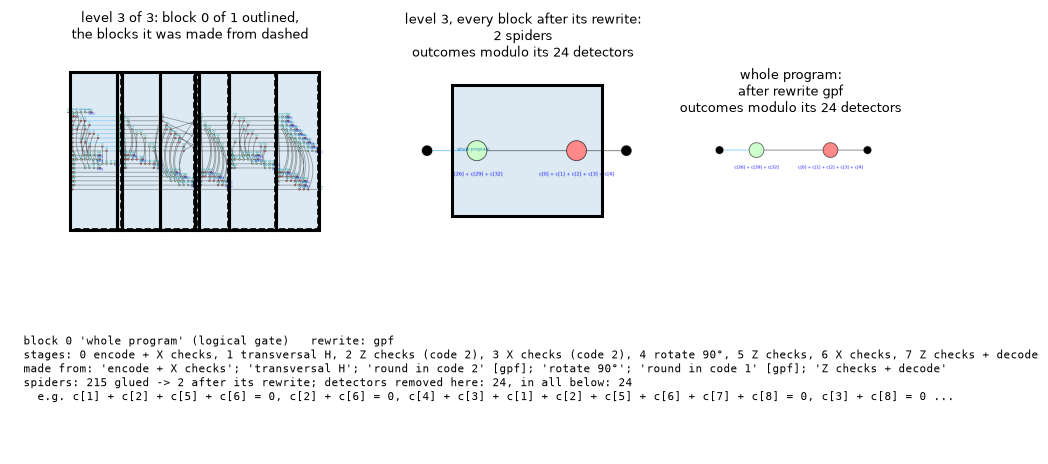

In [13]:
import interactive_fold_h_levels as window       # build: the three levels of the window
r, levels = window.build(miswired=False)
for level in levels:
    print(r.describe_reduced(level))
view = view_levels(r, levels[-1], 0, controls=False, figsize=(9, 5.2), program_figsize=(14, 8),
                   level_figsize=(7, 4), block_figsize=(6, 1.6))
view

## In short

Reading the code at every cut is what lets the tool check a program that changes codes: it finds the swap and the quarter turn that undoes it, calls the transversal Hadamard a logical Hadamard, and shows the wiring mistake as a stage where the code can no longer catch a single error.